# 02 — Baseline: TF-IDF + linear models

Creates the **fixed group-aware validation split** used by every later notebook, then TF-IDF word/char n-grams with classical models, a small parameter search, per-class metrics and a confusion matrix.

**Run on Kaggle**
1. *Create → New Notebook → File → Import Notebook* → upload this file.
2. *Settings*: Accelerator **None (CPU)**.
3. *Add Input*: competition **ai-generated-text-detection-hw3-ucu-ai-2026**.
4. *Save Version → Save & Run All (Commit)*. **ETA: ~1–1.5 h.**

**Copy back into the repo** (from the version's *Output* tab):
- this notebook with outputs → `notebooks/02_baseline.ipynb`
- `split.csv` → `data/splits/`
- `baseline_results.csv`, `cm_*.png` → `reports/` and `reports/figures/`
- keep `baseline.joblib`, `baseline_*_scores.csv` only on Kaggle (inputs of 04/05)


In [1]:
import os, glob, re, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

SMOKE = bool(os.environ.get('SMOKE'))  # tiny local dry-run of the whole notebook; never set on Kaggle
OUT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
OUT.mkdir(exist_ok=True)
SEED, LABELS = 42, ['human', 'ai', 'fusion']
L2I = {l: i for i, l in enumerate(LABELS)}

def find(name):
    """Locate an input file in attached Kaggle inputs (or ../data locally)."""
    for root in ['/kaggle/input', '../data', str(OUT)]:
        hits = sorted(glob.glob(f'{root}/**/{name}', recursive=True))
        if hits:
            return hits[0]
    raise FileNotFoundError(f'{name} not found: attach the inputs listed at the top of this notebook')

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")  # the competition metric

def report(y_true, y_pred, title):
    """Per-class metrics + normalized confusion matrix (labels are class indices)."""
    print(f'{title}: macro-F1 = {macro_f1(y_true, y_pred):.4f}')
    print(classification_report(y_true, y_pred, target_names=LABELS, digits=4))
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap='Blues', values_format='.3f')
    plt.title(title); plt.grid(False)
    plt.savefig(OUT / f"cm_{re.sub(r'[^a-z0-9]+', '_', title.lower())}.png", dpi=120, bbox_inches='tight'); plt.show()

def f1_by(df, pred_col, by):
    return df.groupby(by).apply(lambda d: macro_f1(d.y, d[pred_col])).round(4).rename('macro_f1').to_frame().join(df[by].value_counts().rename('n'))

train = pd.read_csv(find('train.csv'))
test = pd.read_csv(find('test.csv'))
sub = pd.read_csv(find('sample_submission.csv'))
if SMOKE:
    test = test.head(300); sub = sub[sub.id.isin(test.id)]
train['y'] = train.label.map(L2I)
print(train.shape, test.shape)

(272352, 6) (25000, 4)


## 1. Fixed validation split

Group-aware (texts linked by shared first/last 10 words stay together), stratified by label × language × domain, 10% of train. A fixed train sample (`sample_rank`) is drawn from the rest: the baseline uses 60k rows, the encoder the first 40k by rank, the perplexity model the first 20k. Vectorizers and models are fit on train rows only.

In [2]:
from scipy import sparse
from scipy.sparse.csgraph import connected_components

def make_groups(texts):
    """Link texts that share their first or last 10 words (a human text and its fusion/ai rewrite) into groups."""
    w = texts.str.lower().str.split()
    keys = pd.concat([w.str[:10].str.join(' ').radd('h:'), w.str[-10:].str.join(' ').radd('t:')], ignore_index=True)
    rows = np.tile(np.arange(len(texts)), 2)
    codes, uniq = pd.factorize(keys)
    keep = np.bincount(codes)[codes] <= 20  # very common openings/closings are boilerplate, not rewrites
    n = len(texts)
    g = sparse.coo_matrix((np.ones(keep.sum()), (rows[keep], n + codes[keep])), shape=(n + len(uniq),) * 2)
    return connected_components(g, directed=False)[1][:n]

In [3]:
from sklearn.model_selection import StratifiedGroupKFold
TRAIN_N = 3_000 if SMOKE else 60_000

train['group'] = make_groups(train.text)
strata = train.label + '|' + train.lang + '|' + train.domain
_, val_idx = next(StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED).split(train, strata, train.group))
train['is_val'] = False
train.loc[val_idx, 'is_val'] = True
assert not set(train.group[train.is_val]) & set(train.group[~train.is_val]), 'group leak'

rest = train[~train.is_val]
samp = rest.groupby(strata[~train.is_val], group_keys=False).sample(frac=TRAIN_N / len(rest), random_state=SEED)
train['sample_rank'] = -1
train.loc[samp.sample(frac=1, random_state=SEED).index, 'sample_rank'] = np.arange(len(samp))
train[['id', 'group', 'is_val', 'sample_rank']].to_csv(OUT / 'split.csv', index=False)

tr, va = train[train.sample_rank >= 0], train[train.is_val]
print(f'train sample {len(tr)}, val {len(va)}')
pd.concat({'train_sample': tr.label.value_counts(normalize=True), 'val': va.label.value_counts(normalize=True)}, axis=1).round(3)

train sample 60001, val 27451


,train_sample,val
label,,
ai,0.448,0.446
fusion,0.307,0.309
human,0.245,0.245


## 2. TF-IDF features (fit on the train sample only)

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

vecs = {
    'word': TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=300_000, sublinear_tf=True),
    'char': TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=5, max_features=300_000, sublinear_tf=True, lowercase=False),
}
Xtr, Xva = {}, {}
for name, v in vecs.items():
    t = time.time()
    Xtr[name], Xva[name] = v.fit_transform(tr.text), v.transform(va.text)
    print(f'{name}: {Xtr[name].shape[1]} features, {time.time() - t:.0f}s')
Xtr['word+char'], Xva['word+char'] = hstack([Xtr['word'], Xtr['char']]).tocsr(), hstack([Xva['word'], Xva['char']]).tocsr()

word: 300000 features, 135s
char: 300000 features, 518s


## 3. Small parameter search on the fixed val split

Step 1: compare feature sets with LinearSVC over C. Step 2: on the best feature set, compare model families.

In [5]:
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import ComplementNB

results, fitted = [], {}
def run(model_name, make, param, feats):
    t = time.time()
    clf = make(param).fit(Xtr[feats], tr.y)
    f1 = macro_f1(va.y, clf.predict(Xva[feats]))
    results.append({'model': model_name, 'param': param, 'features': feats, 'val_macro_f1': round(f1, 4), 'sec': round(time.time() - t)})
    fitted[(model_name, param, feats)] = clf
    print(results[-1])

for feats in ['word', 'char', 'word+char']:
    for C in [0.1, 0.3, 1.0]:
        run('LinearSVC', lambda C: LinearSVC(C=C, dual=True, random_state=SEED), C, feats)

{'model': 'LinearSVC', 'param': 0.1, 'features': 'word', 'val_macro_f1': 0.8267, 'sec': 6}
{'model': 'LinearSVC', 'param': 0.3, 'features': 'word', 'val_macro_f1': 0.8372, 'sec': 8}
{'model': 'LinearSVC', 'param': 1.0, 'features': 'word', 'val_macro_f1': 0.837, 'sec': 14}
{'model': 'LinearSVC', 'param': 0.1, 'features': 'char', 'val_macro_f1': 0.8481, 'sec': 30}
{'model': 'LinearSVC', 'param': 0.3, 'features': 'char', 'val_macro_f1': 0.8586, 'sec': 37}
{'model': 'LinearSVC', 'param': 1.0, 'features': 'char', 'val_macro_f1': 0.8589, 'sec': 62}
{'model': 'LinearSVC', 'param': 0.1, 'features': 'word+char', 'val_macro_f1': 0.8571, 'sec': 38}
{'model': 'LinearSVC', 'param': 0.3, 'features': 'word+char', 'val_macro_f1': 0.8663, 'sec': 51}
{'model': 'LinearSVC', 'param': 1.0, 'features': 'word+char', 'val_macro_f1': 0.8657, 'sec': 94}


In [6]:
best_feats = max(results, key=lambda r: r['val_macro_f1'])['features']
for C in [10.0, 30.0, 100.0]:
    run('LogReg', lambda C: LogisticRegression(C=C, max_iter=1000, random_state=SEED), C, best_feats)
for a in [0.03, 0.1, 0.3]:
    run('ComplementNB', lambda a: ComplementNB(alpha=a), a, best_feats)
for a in [1e-6, 1e-5]:
    run('SGD-modhuber', lambda a: SGDClassifier(loss='modified_huber', alpha=a, max_iter=30, random_state=SEED), a, best_feats)

res = pd.DataFrame(results).sort_values('val_macro_f1', ascending=False)
res.to_csv(OUT / 'baseline_results.csv', index=False)
res

{'model': 'LogReg', 'param': 10.0, 'features': 'word+char', 'val_macro_f1': 0.8796, 'sec': 490}
{'model': 'LogReg', 'param': 30.0, 'features': 'word+char', 'val_macro_f1': 0.8793, 'sec': 346}
{'model': 'LogReg', 'param': 100.0, 'features': 'word+char', 'val_macro_f1': 0.878, 'sec': 350}
{'model': 'ComplementNB', 'param': 0.03, 'features': 'word+char', 'val_macro_f1': 0.6568, 'sec': 3}
{'model': 'ComplementNB', 'param': 0.1, 'features': 'word+char', 'val_macro_f1': 0.6541, 'sec': 3}
{'model': 'ComplementNB', 'param': 0.3, 'features': 'word+char', 'val_macro_f1': 0.6499, 'sec': 3}
{'model': 'SGD-modhuber', 'param': 1e-06, 'features': 'word+char', 'val_macro_f1': 0.8596, 'sec': 43}
{'model': 'SGD-modhuber', 'param': 1e-05, 'features': 'word+char', 'val_macro_f1': 0.8648, 'sec': 25}


,model,param,features,val_macro_f1,sec
9,LogReg,10.000000,word+char,0.8796,490
10,LogReg,30.000000,word+char,0.8793,346
11,LogReg,100.000000,word+char,0.8780,350
7,LinearSVC,0.300000,word+char,0.8663,51
8,LinearSVC,1.000000,word+char,0.8657,94
16,SGD-modhuber,0.000010,word+char,0.8648,25
15,SGD-modhuber,0.000001,word+char,0.8596,43
5,LinearSVC,1.000000,char,0.8589,62
4,LinearSVC,0.300000,char,0.8586,37
6,LinearSVC,0.100000,word+char,0.8571,38


**Observations.** Character n-grams beat word n-grams (LinearSVC 0.859 vs 0.837), and combining both is best (0.866). On word+char, logistic regression (C=10, 0.880) beats LinearSVC by ~0.013; C hardly matters between 10 and 100. ComplementNB is far behind (0.657) and SGD is close to LinearSVC. Best config: **LogReg C=10 on word+char TF-IDF**.

## 4. Best baseline: per-class metrics, confusion matrix, overfitting check

best: ('LogReg', np.float64(10.0), 'word+char')
train macro-F1 0.9983  vs  val 0.8796  (gap = overfitting)
Baseline val: macro-F1 = 0.8796
              precision    recall  f1-score   support

       human     0.7889    0.8516    0.8190      6723
          ai     0.9800    0.9908    0.9853     12239
      fusion     0.8701    0.8015    0.8344      8489

    accuracy                         0.8981     27451
   macro avg     0.8796    0.8813    0.8796     27451
weighted avg     0.8992    0.8981    0.8979     27451



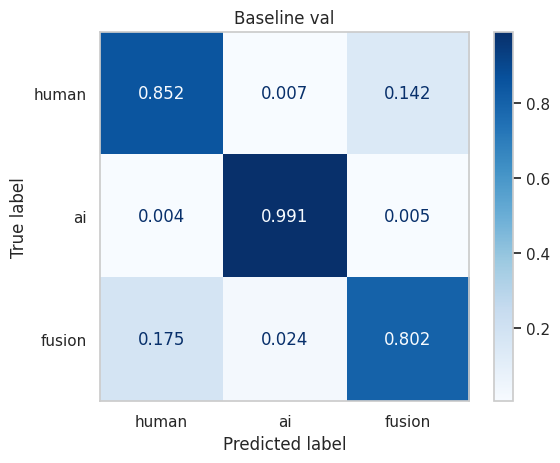

In [7]:
best = res.iloc[0]
key = (best.model, best.param, best.features)
clf = fitted[key]
va = va.assign(pred=clf.predict(Xva[best.features]))
print('best:', key)
print(f'train macro-F1 {macro_f1(tr.y, clf.predict(Xtr[best.features])):.4f}  vs  val {macro_f1(va.y, va.pred):.4f}  (gap = overfitting)')
report(va.y, va.pred, 'Baseline val')

In [8]:
display(f1_by(va, 'pred', 'lang'), f1_by(va, 'pred', 'domain'))

,macro_f1,n
lang,,
de-DE,0.9015,5383
en-EN,0.8737,22068


,macro_f1,n
domain,,
arxiv_papers,0.8559,1378
blog_authorship_corpus,0.7517,4004
bundestag,0.9014,5343
cnn_news,0.9119,4436
euro_court_cases,0.9060,2776
gutenberg,0.8885,723
house_of_commons,0.8790,3117
student_essays,0.8984,5674


**Observations.** `ai` is almost solved (F1 0.985). The errors are **human ↔ fusion** (F1 0.819 / 0.834; recall 0.85 / 0.80, with almost all misses going to the other of the two classes). Train macro-F1 is 0.998 vs 0.880 on val: 600k features on 60k rows overfit strongly, so more training data should help (→ 02b). German scores higher than English (0.90 vs 0.87). The weakest domain is blogs (0.75).

## 5. Save scores for stacking (04) and the baseline submission

In [9]:
def scores(X):
    return clf.decision_function(X) if hasattr(clf, 'decision_function') else clf.predict_log_proba(X)

def featurize(texts):
    parts = [vecs[n].transform(texts) for n in best.features.split('+')]
    return hstack(parts).tocsr() if len(parts) > 1 else parts[0]

cols = [f'base_{l}' for l in LABELS]
pd.DataFrame(scores(Xva[best.features]), columns=cols).assign(id=va.id.values).to_csv(OUT / 'baseline_val_scores.csv', index=False)
te = scores(featurize(test.text))
pd.DataFrame(te, columns=cols).assign(id=test.id.values).to_csv(OUT / 'baseline_test_scores.csv', index=False)

pred = pd.DataFrame({'id': test.id, 'label': np.array(LABELS)[te.argmax(1)]})
submission = sub[['id']].merge(pred, on='id', how='left')
assert len(submission) == len(sub) and submission.label.isin(LABELS).all()
submission.to_csv(OUT / 'submission_baseline.csv', index=False)
print(submission.label.value_counts(normalize=True).round(3))

label
ai        0.519
human     0.265
fusion    0.216
Name: proportion, dtype: float64


In [10]:
import joblib
for v in vecs.values():
    v.__dict__.pop('stop_words_', None)  # pruned-terms set is huge and not needed for transform
joblib.dump({'vecs': vecs, 'clf': clf, 'features': best.features}, OUT / 'baseline.joblib', compress=3)

['/kaggle/working/baseline.joblib']